# Garbage Classification — Tiền xử lý (PyTorch)

Notebook nối tiếp `EDA.ipynb` và dùng chung các hàm trong **`preprocessing.py`**.
Chạy các ô từ trên xuống để kiểm tra ảnh, sửa nhãn, loại trùng byte, chia tập,
lưu CSV, tính trọng số lớp và kiểm tra DataLoader. Cần cài torch, torchvision,
numpy, pandas, Pillow, scikit-learn và matplotlib trong môi trường kernel.

Ảnh gốc được giữ tại `data/raw/garbage_classification`; CSV chứa đường dẫn tương đối.
Các tập train/val/test dùng tỉ lệ 70/15/15 và seed 42. Cả nhóm dùng chung CSV đã tạo.
Sửa nhãn tập trung tại `LABEL_CORRECTIONS` trong `preprocessing.py`, rồi khởi động lại
kernel và chạy lại notebook để cập nhật.

**Dùng trong notebook model:** sửa đường dẫn dự án trong ví dụ sau.

```python
from pathlib import Path
import sys
import torch

PROJECT_DIR = Path(r'C:/duong_dan/deep_learning-waste_classification')
sys.path.insert(0, str(PROJECT_DIR / 'preprocess'))
from preprocessing import CLASSES, make_dataloaders, compute_class_weights

train_loader, val_loader, test_loader = make_dataloaders(
    img_size=224, batch_size=32, seed=42, num_workers=0,
    csv_dir=PROJECT_DIR / 'data',
    data_dir=PROJECT_DIR / 'data/raw/garbage_classification',
)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
class_weights = compute_class_weights(PROJECT_DIR / 'data/train/train.csv')
criterion = torch.nn.CrossEntropyLoss(weight=class_weights.to(device))
```

Ảnh có shape `(batch, 3, 224, 224)`, dtype `torch.float32`, pixel trong `[0, 1]`.
Nhãn là số nguyên 0–11 theo `CLASSES`. Simple/Complex CNN trả về 12 logits để dùng
`CrossEntropyLoss`; đưa ảnh, nhãn và model lên cùng device. Pipeline đã chia 255
và augmentation cho train. Chỉ dùng test sau khi chọn checkpoint bằng validation.



In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

# Hỗ trợ chạy notebook từ thư mục dự án hoặc thư mục preprocess.
pipeline_candidates = [
    candidate
    for base in (Path.cwd(), *Path.cwd().parents)
    for candidate in (base / 'preprocess', base)
    if (candidate / 'preprocessing.py').is_file()
]
if not pipeline_candidates:
    raise FileNotFoundError('Không tìm thấy preprocess/preprocessing.py. Kiểm tra thư mục làm việc.')
sys.path.insert(0, str(pipeline_candidates[0].resolve()))

from preprocessing import (
    SEED, IMG_SIZE, BATCH_SIZE, VAL_RATIO, TEST_RATIO, CLASSES,
    LABEL_CORRECTIONS, AugmentConfig, find_data_dir, get_csv_dir,
    seed_everything, scan_images, find_cross_label_duplicates,
    apply_label_corrections, remove_same_label_duplicates,
    split_dataset, save_splits, compute_class_weights,
    make_dataloaders, show_batch,
)

seed_everything(SEED)
DATA_DIR = find_data_dir()
CSV_DIR = get_csv_dir(DATA_DIR)
print('Thư mục dữ liệu:', DATA_DIR)
print('Thư mục CSV:', CSV_DIR)
print('Kích thước ảnh:', IMG_SIZE, '| Batch size:', BATCH_SIZE)


Thư mục dữ liệu: C:\Users\Lenovo\Documents\Deep Learning\Mid-term Project\deep_learning-waste_classification\data\raw\garbage_classification
Thư mục CSV: C:\Users\Lenovo\Documents\Deep Learning\Mid-term Project\deep_learning-waste_classification\data
Kích thước ảnh: 224 | Batch size: 32


## Bước 1. Kiểm kê lại dữ liệu

`scan_images()` kiểm tra ảnh đọc được, tính SHA-256 và xác nhận nhãn nằm trong
`CLASSES`. Ảnh lỗi được báo và bỏ qua; dừng nếu không có ảnh hợp lệ.


In [2]:
df = scan_images(DATA_DIR)
display(df.head())


[scan] Tổng số ảnh hợp lệ: 15,515


,filepath,label,file_hash
0,battery/battery1.jpg,battery,65d0311205cb0148871bc14dec13314c0209ecd74095f9...
1,battery/battery10.jpg,battery,334466b4324a8c80f3204ef4c63cf6892ec20a954880af...
2,battery/battery100.jpg,battery,32efd926e244739e97b3ced8bd3b9e2ce01ca101972eb5...
3,battery/battery101.jpg,battery,49a84a86143beab927b8074c2d05855e4221c4e99137d5...
4,battery/battery102.jpg,battery,7e191fef8b4cd286fb635cf99ede490dc598c42c39df9c...


## Bước 2. Phát hiện và sửa nhãn

In các nhóm ảnh trùng byte nhưng khác nhãn để đối chiếu. Áp dụng bảng sửa nhãn
`LABEL_CORRECTIONS` dùng chung trong `preprocessing.py`:

| File | Nhãn đúng |
|---|---|
| `metal/metal459.jpg` | white-glass |
| `plastic/plastic159.jpg` | white-glass |
| `white-glass/white-glass761.jpg` | plastic |

Nhật ký sửa nhãn được lưu cùng CSV ở Bước 5.


In [3]:
cross_label_groups = find_cross_label_duplicates(df)
print('Số nhóm trùng khác nhãn:', len(cross_label_groups))
for group in cross_label_groups:
    print(group)

display(pd.Series(LABEL_CORRECTIONS, name='correct_label').rename_axis('filepath').to_frame())
df, applied_df = apply_label_corrections(df)
display(applied_df)


Số nhóm trùng khác nhãn: 3
[('metal/metal459.jpg', 'metal'), ('white-glass/white-glass412.jpg', 'white-glass')]
[('plastic/plastic556.jpg', 'plastic'), ('white-glass/white-glass761.jpg', 'white-glass')]
[('plastic/plastic159.jpg', 'plastic'), ('white-glass/white-glass129.jpg', 'white-glass')]


,correct_label
filepath,
metal/metal459.jpg,white-glass
plastic/plastic159.jpg,white-glass
white-glass/white-glass761.jpg,plastic


[labels] Đã sửa nhãn 3 ảnh.


,filepath,old_label,new_label
0,metal/metal459.jpg,metal,white-glass
1,plastic/plastic159.jpg,plastic,white-glass
2,white-glass/white-glass761.jpg,white-glass,plastic


## Bước 3. Loại ảnh trùng cùng nhãn

`remove_same_label_duplicates()` giữ file có đường dẫn nhỏ nhất trong mỗi nhóm
trùng cùng nhãn và loại các bản còn lại khỏi danh sách. Ảnh gốc vẫn được giữ.
Nếu còn nhóm trùng khác nhãn, hàm dừng để sửa nhãn trước khi chia tập.


In [4]:
before = len(df)
df, removed_df = remove_same_label_duplicates(df)
print(f'Số ảnh trước/sau khi loại trùng: {before:,} / {len(df):,}')
display(removed_df.head())


[dedup] Đã bỏ 19 ảnh trùng cùng nhãn, còn 15,496 ảnh.
Số ảnh trước/sau khi loại trùng: 15,515 / 15,496


,removed_filepath,kept_filepath,label
0,green-glass/green-glass555.jpg,green-glass/green-glass285.jpg,green-glass
1,green-glass/green-glass564.jpg,green-glass/green-glass403.jpg,green-glass
2,green-glass/green-glass492.jpg,green-glass/green-glass476.jpg,green-glass
3,green-glass/green-glass554.jpg,green-glass/green-glass336.jpg,green-glass
4,green-glass/green-glass565.jpg,green-glass/green-glass449.jpg,green-glass


## Bước 4. Phân bố lớp sau khi làm sạch

Xem lại phân bố lớp sau dedup + sửa nhãn, để biết mức độ lệch lớp thực tế sẽ dùng khi tính class weight.


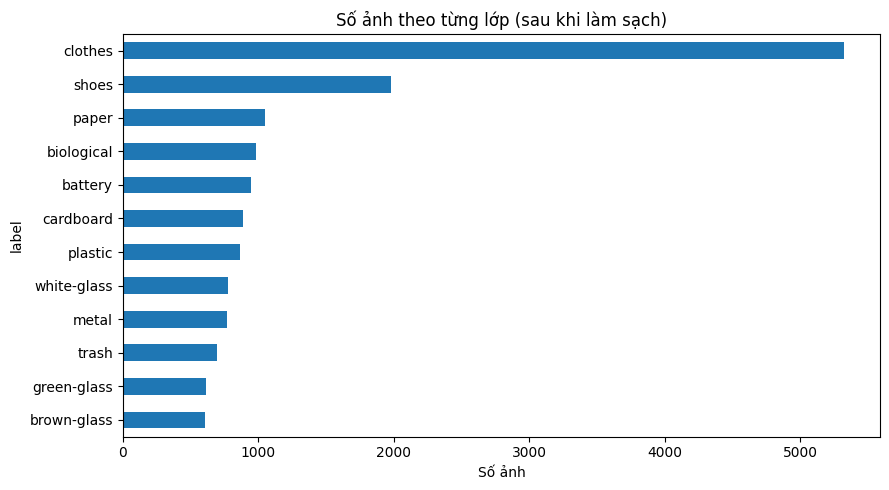

Tổng số ảnh: 15,496
Lệch lớp (max/min): 8.77 lần


In [5]:
counts = df['label'].value_counts().reindex(CLASSES, fill_value=0)

if (counts == 0).any():
    raise ValueError(f'Dữ liệu thiếu lớp: {counts[counts == 0].index.tolist()}')

fig, ax = plt.subplots(figsize=(9, 5))
counts.sort_values().plot(kind='barh', ax=ax)
ax.set_xlabel('Số ảnh')
ax.set_title('Số ảnh theo từng lớp (sau khi làm sạch)')
plt.tight_layout()
plt.show()

print(f'Tổng số ảnh: {len(df):,}')
print(f'Lệch lớp (max/min): {counts.max() / counts.min():.2f} lần')


## Bước 5. Chia train/val/test (stratified)

Chia trên **danh sách file đã làm sạch**, chưa đọc pixel ảnh — chỉ cần cột `filepath` và `label`.
Dùng `stratify=label` để giữ đúng tỉ lệ 12 lớp ở cả 3 tập.

Lưu ý: hiện chỉ loại ảnh trùng byte (SHA-256 file). Các cặp gần trùng pHash chưa được xử lý; cần kiểm tra nguy cơ ảnh gần trùng nằm ở các tập khác nhau trước khi đánh giá mô hình.


In [6]:
train_df, val_df, test_df = split_dataset(
    df, val_ratio=VAL_RATIO, test_ratio=TEST_RATIO, seed=SEED,
)
save_splits(train_df, val_df, test_df, CSV_DIR, applied_df, removed_df)

display(pd.DataFrame({
    'train': train_df.label.value_counts().reindex(CLASSES, fill_value=0),
    'val': val_df.label.value_counts().reindex(CLASSES, fill_value=0),
    'test': test_df.label.value_counts().reindex(CLASSES, fill_value=0),
}))


[split] Train: 10,847 | Val: 2,324 | Test: 2,325
[save] Đã lưu CSV vào C:\Users\Lenovo\Documents\Deep Learning\Mid-term Project\deep_learning-waste_classification\data


,train,val,test
label,,,
battery,661,142,142
biological,689,148,148
brown-glass,425,91,91
cardboard,624,133,134
clothes,3727,798,799
green-glass,430,92,92
metal,537,116,115
paper,735,157,158
plastic,605,130,129


## Bước 6. Trọng số lớp từ tập train

`compute_class_weights()` trả về tensor float32 theo thứ tự `CLASSES`, với công
thức `N_train / (12 × số ảnh train của lớp)`. Dùng tensor này trong
`torch.nn.CrossEntropyLoss(weight=...)`, chuyển trọng số lên cùng device với model.


In [7]:
class_weights = compute_class_weights(CSV_DIR / 'train' / 'train.csv')
for name, weight in zip(CLASSES, class_weights):
    print(f'{name:<14} -> {weight.item():.3f}')
criterion = torch.nn.CrossEntropyLoss(weight=class_weights)


battery        -> 1.367
biological     -> 1.312
brown-glass    -> 2.127
cardboard      -> 1.449
clothes        -> 0.243
green-glass    -> 2.102
metal          -> 1.683
paper          -> 1.230
plastic        -> 1.494
shoes          -> 0.653
trash          -> 1.852
white-glass    -> 1.668


## Bước 7. RGB, resize giữ tỉ lệ và tạo DataLoader

`make_dataloaders()` dùng `GarbageDataset` để đọc ảnh theo CSV, chuyển RGB,
resize giữ tỉ lệ và thêm viền đen thành ảnh vuông 224×224. `ToTensor()` chuyển
pixel về `[0, 1]` với thứ tự kênh `(C, H, W)`.

Chỉ train được shuffle và augmentation; val/test giữ thứ tự và không augmentation.
Dùng `num_workers=0` để chạy trực tiếp trong notebook trên Windows.
`cache_resized=False` đọc ảnh khi cần, tránh cache toàn bộ dữ liệu vào RAM.


In [8]:
aug_config = AugmentConfig()
train_loader, val_loader, test_loader = make_dataloaders(
    img_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=SEED,
    csv_dir=CSV_DIR, data_dir=DATA_DIR, aug_config=aug_config,
    num_workers=0, cache_resized=False,
)
print('Đã tạo train_loader, val_loader, test_loader.')


Đã tạo train_loader, val_loader, test_loader.


## Bước 8. Augmentation chỉ cho train

Cấu hình mặc định từ `AugmentConfig`: lật ngang (p=0.5), lật dọc (p=0.2),
xoay trong ±15° (p=0.5), thay đổi độ sáng (p=0.5) và tương phản (p=0.5)
với hệ số trong `[0.85, 1.15]`. Các phép biến đổi được áp dụng sau resize và
trước `ToTensor()`. Val/test chỉ resize và chuyển tensor.

Chỉnh `aug_config` tại Bước 7 rồi tạo lại DataLoader nếu muốn đổi tham số.


In [9]:
print('Cấu hình augmentation train:', aug_config)
for name, loader in [('train', train_loader), ('val', val_loader), ('test', test_loader)]:
    print(f'{name}: {loader.dataset.postprocess}')


Cấu hình augmentation train: AugmentConfig(hflip_p=0.5, vflip_p=0.2, rotation_p=0.5, rotation_degrees=15.0, brightness_p=0.5, brightness_delta=0.15, contrast_p=0.5, contrast_delta=0.15, fill=0)
train: Compose(
    Compose(
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.2)
    RandomApply(
    p=0.5
    RandomRotation(degrees=[-15.0, 15.0], interpolation=bilinear, expand=False, fill=0)
)
    RandomApply(
    p=0.5
    ColorJitter(brightness=(0.85, 1.15), contrast=None, saturation=None, hue=None)
)
    RandomApply(
    p=0.5
    ColorJitter(brightness=None, contrast=(0.85, 1.15), saturation=None, hue=None)
)
)
    ToTensor()
)
val: Compose(
    ToTensor()
)
test: Compose(
    ToTensor()
)


## Bước 9. Kiểm tra batch và xem ảnh

Kiểm tra shape `(B, 3, IMG_SIZE, IMG_SIZE)`, dtype, miền pixel và nhãn của cả
ba tập. `show_batch()` chuyển tensor từ `(C, H, W)` sang `(H, W, C)` để hiển thị.


train: shape=(32, 3, 224, 224), dtype=torch.float32, pixel=[0.000, 1.000]


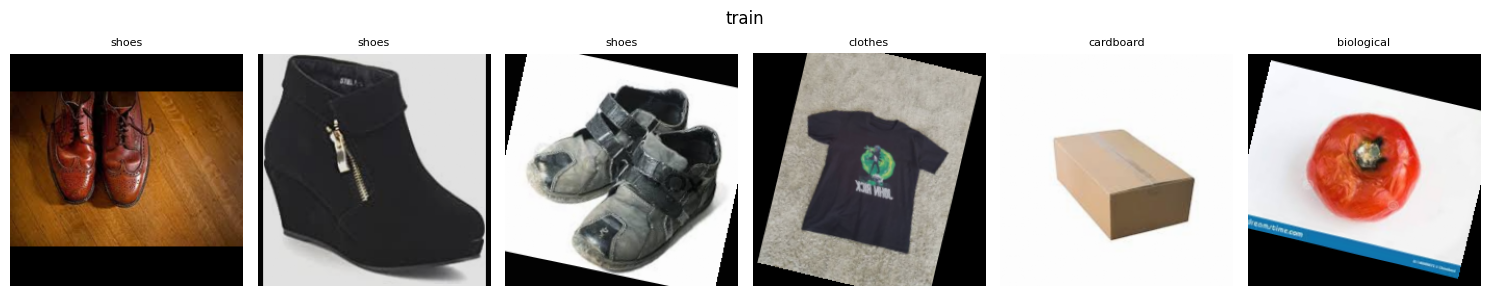

val: shape=(32, 3, 224, 224), dtype=torch.float32, pixel=[0.000, 1.000]


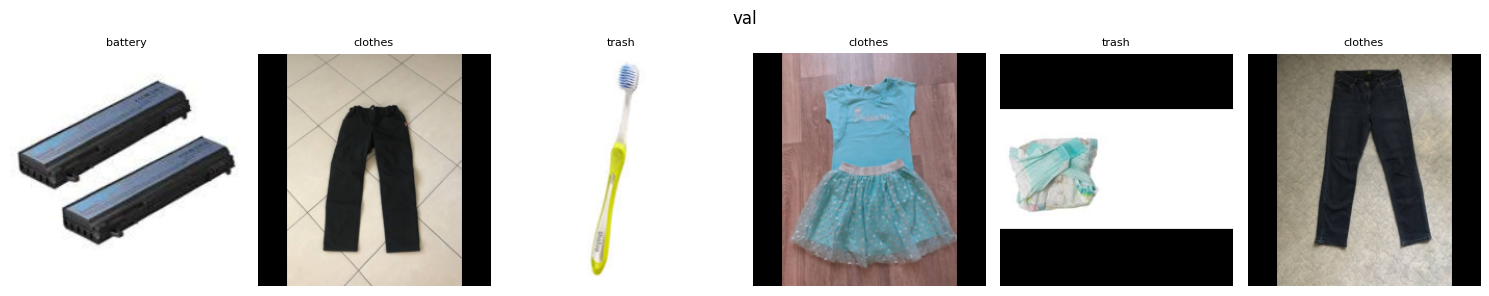

test: shape=(32, 3, 224, 224), dtype=torch.float32, pixel=[0.000, 1.000]


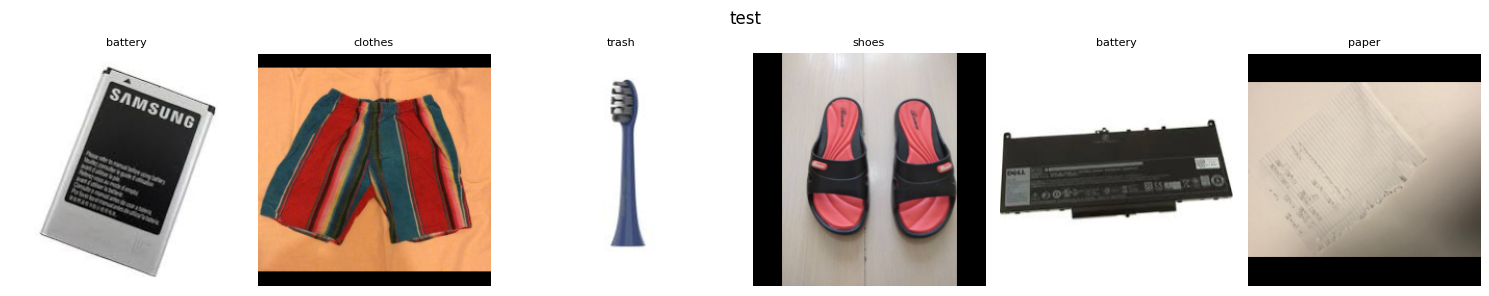

In [10]:
for name, loader in [('train', train_loader), ('val', val_loader), ('test', test_loader)]:
    images, labels = next(iter(loader))
    assert tuple(images.shape[1:]) == (3, IMG_SIZE, IMG_SIZE)
    assert images.dtype == torch.float32
    assert torch.isfinite(images).all()
    assert 0.0 <= images.min() and images.max() <= 1.0
    assert labels.dtype == torch.int64
    assert 0 <= labels.min() and labels.max() < len(CLASSES)
    print(f'{name}: shape={tuple(images.shape)}, dtype={images.dtype}, '
          f'pixel=[{images.min().item():.3f}, {images.max().item():.3f}]')
    show_batch(loader, n=6, title=name)


## Tổng kết bước tiền xử lý

In [11]:
print(f'Ảnh sau làm sạch: {len(df):,}')
print(f'Train / Val / Test: {len(train_df):,} / {len(val_df):,} / {len(test_df):,}')
print(f'Ảnh đầu vào: (B, 3, {IMG_SIZE}, {IMG_SIZE}), pixel [0, 1], batch size {BATCH_SIZE}')
print('Trọng số lớp: tensor dùng trong torch.nn.CrossEntropyLoss.')
print('Augmentation và shuffle chỉ áp dụng cho train_loader.')
print('CSV và nhật ký:')
for relative in (
    'train/train.csv', 'val/val.csv', 'test/test.csv',
    'processed/label_corrections_applied.csv', 'processed/removed_duplicates.csv',
):
    print(' ', CSV_DIR / relative)


Ảnh sau làm sạch: 15,496
Train / Val / Test: 10,847 / 2,324 / 2,325
Ảnh đầu vào: (B, 3, 224, 224), pixel [0, 1], batch size 32
Trọng số lớp: tensor dùng trong torch.nn.CrossEntropyLoss.
Augmentation và shuffle chỉ áp dụng cho train_loader.
CSV và nhật ký:
  C:\Users\Lenovo\Documents\Deep Learning\Mid-term Project\deep_learning-waste_classification\data\train\train.csv
  C:\Users\Lenovo\Documents\Deep Learning\Mid-term Project\deep_learning-waste_classification\data\val\val.csv
  C:\Users\Lenovo\Documents\Deep Learning\Mid-term Project\deep_learning-waste_classification\data\test\test.csv
  C:\Users\Lenovo\Documents\Deep Learning\Mid-term Project\deep_learning-waste_classification\data\processed\label_corrections_applied.csv
  C:\Users\Lenovo\Documents\Deep Learning\Mid-term Project\deep_learning-waste_classification\data\processed\removed_duplicates.csv
